<a href="https://colab.research.google.com/github/sachitsaz/Computer-Vision/blob/main/3D-CV/01_Depth_Anything/cv_05_1_Depth8_dataset_DepthAnything.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Ultralytics Depth8 dataset, a compact set of 8 indoor RGB-D images for testing monocular depth estimation models and training pipelines

The Ultralytics Depth8 dataset is a compact dataset for testing monocular depth-estimation pipelines. It contains eight RGB images sampled from the SUN RGB-D dataset: four for training and four for validation, drawn from Kinect v1 and Kinect v2 captures. The images are paired with dense ground-truth depth maps.

**Source:** [Ultralytics Depth8 Dataset Documentation](https://github.com/ultralytics/ultralytics/blob/main/docs/en/datasets/depth/depth8.md)

**Limitation:** Depth8 is intended for pipeline testing and debugging, not benchmarking, because its eight images are insufficient for meaningful performance evaluation.

In [ ]:
import os
import zipfile
import urllib.request
import numpy as np
from PIL import Image
from google.colab import drive
import shutil
import matplotlib.pyplot as plt

In [ ]:
# ============================================================
# Download official Ultralytics Depth8 and create:
#
# image_01.png
# depth_01.npy
# ...
# image_08.png
# depth_08.npy
#
# Ground-truth depth is saved in METERS.
# ============================================================

# 1. URLs and folders
# ------------------------------------------------------------

url = "https://github.com/ultralytics/assets/releases/download/v0.0.0/depth8-png.zip"

zip_path = "/content/depth8-png.zip"
extract_dir = "/content/depth8_original"
output_dir = "/content/Depth8_8pairs"

os.makedirs(output_dir, exist_ok=True)


# ------------------------------------------------------------
# 2. Download official Depth8 ZIP
# ------------------------------------------------------------

print("Downloading Depth8...")

urllib.request.urlretrieve(
    url,
    zip_path
)

print("Download complete.")


# ------------------------------------------------------------
# 3. Extract ZIP
# ------------------------------------------------------------

print("Extracting...")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

print("Extraction complete.")


# ------------------------------------------------------------
# 4. Find image/depth folders
# ------------------------------------------------------------

image_files = []

for root, dirs, files in os.walk(extract_dir):

    if "images" in root.replace("\\", "/").split("/"):
        for file in files:
            if file.lower().endswith((".png", ".jpg", ".jpeg")):
                image_files.append(
                    os.path.join(root, file)
                )

image_files = sorted(image_files)


print(f"Found {len(image_files)} RGB images.")


# ------------------------------------------------------------
# 5. Find corresponding depth maps
# ------------------------------------------------------------

saved = 0

for rgb_path in image_files:

    # Find filename
    filename = os.path.basename(rgb_path)
    stem = os.path.splitext(filename)[0]

    # Replace images/... with depth/...
    normalized = rgb_path.replace("\\", "/")

    if "/images/" not in normalized:
        continue

    depth_path = normalized.replace(
        "/images/",
        "/depth/"
    )

    # Change extension to PNG
    depth_path = os.path.splitext(depth_path)[0] + ".png"

    if not os.path.exists(depth_path):
        print("Depth not found:", depth_path)
        continue


    # --------------------------------------------------------
    # Read RGB
    # --------------------------------------------------------

    rgb = Image.open(rgb_path).convert("RGB")


    # --------------------------------------------------------
    # Read 16-bit depth
    # --------------------------------------------------------

    depth_mm = np.array(
        Image.open(depth_path),
        dtype=np.uint16
    )


    # --------------------------------------------------------
    # Convert millimeters -> meters
    # Official Depth8 depth_scale = 1000
    # --------------------------------------------------------

    depth_m = depth_mm.astype(
        np.float32
    ) / 1000.0


    # --------------------------------------------------------
    # Save with our naming convention
    # --------------------------------------------------------

    saved += 1

    rgb_output = os.path.join(
        output_dir,
        f"image_{saved:02d}.png"
    )

    depth_output = os.path.join(
        output_dir,
        f"depth_{saved:02d}.npy"
    )


    rgb.save(rgb_output)

    np.save(
        depth_output,
        depth_m
    )


    print(
        f"{saved:02d}: "
        f"{rgb.size} | "
        f"depth={depth_m.shape} | "
        f"depth range={depth_m.min():.3f}–{depth_m.max():.3f} m"
    )


# ------------------------------------------------------------
# 6. Final summary
# ------------------------------------------------------------

print("\n========================================")
print("DONE")
print("========================================")
print("Number of RGB-depth pairs:", saved)
print("Output folder:", output_dir)

print("\nFiles:")

for file in sorted(os.listdir(output_dir)):
    print(file)

Download complete.
Extracting...
Extraction complete.
Found 8 RGB images.
01: (561, 427) | depth=(427, 561) | depth range=0.963–3.080 m
02: (561, 427) | depth=(427, 561) | depth range=1.989–3.824 m
03: (730, 530) | depth=(530, 730) | depth range=0.782–2.344 m
04: (730, 530) | depth=(530, 730) | depth range=0.667–3.159 m
05: (561, 427) | depth=(427, 561) | depth range=1.757–3.328 m
06: (561, 427) | depth=(427, 561) | depth range=1.469–3.627 m
07: (730, 530) | depth=(530, 730) | depth range=0.528–2.066 m
08: (730, 530) | depth=(530, 730) | depth range=0.561–2.391 m

DONE
Number of RGB-depth pairs: 8
Output folder: /content/Depth8_8pairs

Files:
depth_01.npy
depth_02.npy
depth_03.npy
depth_04.npy
depth_05.npy
depth_06.npy
depth_07.npy
depth_08.npy
image_01.png
image_02.png
image_03.png
image_04.png
image_05.png
image_06.png
image_07.png
image_08.png


The important point is that depth_XX.npy contains meters, not the original integer millimeters. For example, an original pixel value of 1500 becomes 1.5 in the NumPy array. This follows the official Depth8 depth_scale: 1000 convention.

Code: depth_m = depth_mm.astype(np.float32) / 1000.0

In [ ]:
# Mount Google Drive
drive.mount('/content/drive')

In [ ]:
# Source folder created previously
source_dir = "/content/Depth8_8pairs"

# Destination folder in Google Drive
destination_dir = "/content/drive/MyDrive/Computer Vision/05/Depth8_8pairs"

# Create parent folder if needed
os.makedirs(
    "/content/drive/MyDrive/Computer Vision/05",
    exist_ok=True
)

# Copy dataset to Drive
shutil.copytree(
    source_dir,
    destination_dir,
    dirs_exist_ok=True
)

print("Dataset saved successfully!")
print("Location:")
print(destination_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset saved successfully!
Location:
/content/drive/MyDrive/Computer Vision/05/Depth8_8pairs


In [ ]:
image = Image.open("/content/Depth8_8pairs/image_01.png")
gt_depth = np.load("/content/Depth8_8pairs/depth_01.npy")

print("Image size:", image.size)
print("Depth shape:", gt_depth.shape)
print("Depth dtype:", gt_depth.dtype)
print("Depth min:", gt_depth.min(), "m")
print("Depth max:", gt_depth.max(), "m")
print("Depth mean:", gt_depth.mean(), "m")

Image size: (561, 427)
Depth shape: (427, 561)
Depth dtype: float32
Depth min: 0.963 m
Depth max: 3.08 m
Depth mean: 1.6018717 m


PIL (Image.size) reports: (width, height)

NumPy (array.shape) reports: (height, width)

So both Image and Depth represent:
Width  = 561 pixels, Height = 427 pixels

The RGB image and depth map have identical spatial dimensions. The RGB image is represented as 427×561 pixels with three color channels, while the depth map is represented as a 427×561 single-channel array.

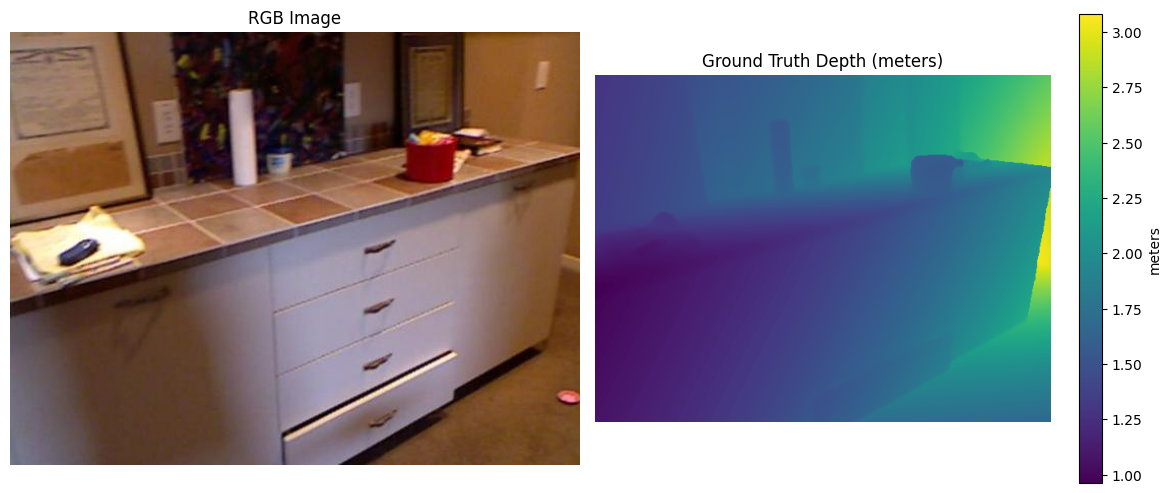

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

image = Image.open(
    "/content/Depth8_8pairs/image_01.png"
)

depth = np.load(
    "/content/Depth8_8pairs/depth_01.npy"
)


plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(image)
plt.title("RGB Image")
plt.axis("off")


plt.subplot(1,2,2)
plt.imshow(depth, cmap="viridis")
plt.title("Ground Truth Depth (meters)")
plt.colorbar(label="meters")
plt.axis("off")

plt.tight_layout()
plt.show()